# Datenanalyse: Mikroplastik-Verschmutzung in Japan (4 Hauptregionen, interpoliert)

Dieses Jupyter Notebook liest die AOMI-Rohdaten direkt ein, fasst die Messpunkte in **4 Hauptregionen** zusammen (Zone 5 *Ogasawara* wurde wegen zu vieler fehlender Werte entfernt), **interpoliert verbleibende Lücken (`NaN`) linear**, berechnet den **Vergleich gegenüber dem Basisjahr 2017** und speichert alle Ergebnisse im Ordner `output/`.

## 1. Setup, Pfade & Daten-Import

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

# Design setzen (ohne seaborn)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (11, 6)

# Pfad zu deiner AOMI-CSV
BASE = Path("/Users/jennyjanac/Desktop/Life/Muros_2026_japan_hsd/Data_sets")
CSV_DATEI = BASE / "data_muros/data/data_download/survey_data.csv"

OUT = Path("output")
OUT.mkdir(exist_ok=True)

print("CSV-Datei gefunden:", CSV_DATEI.exists())

CSV-Datei gefunden: True


## 2. AOMI-Rohdaten einlesen (inkl. automatischem Überspringen des Metadaten-Headers)

In [9]:
if CSV_DATEI.exists():
    header_row = 0
    with open(CSV_DATEI, "r", encoding="utf-8", errors="ignore") as f:
        for idx, line in enumerate(f):
            if line.startswith("0001:Data ID"):
                header_row = idx
                break
                
    df_raw = pd.read_csv(
        CSV_DATEI, 
        skiprows=header_row, 
        encoding="utf-8", 
        low_memory=False,
        on_bad_lines="skip"
    )
    print(f"Erfolgreich geladen! Zeilen: {df_raw.shape[0]}, Spalten: {df_raw.shape[1]}")
else:
    print("HINWEIS: CSV-Datei unter dem angegebenen Pfad nicht gefunden.")

Erfolgreich geladen! Zeilen: 18860, Spalten: 449


## 3. Zusammenfassung in 4 Hauptregionen & Bereinigung (`NaN`-Handling)

1. **Zone 5 (`Ogasawara_OpenOcean`) ausschließen:** Wird aufgrund zu vieler fehlender Messjahre (`NaN`) aus der Analyse entfernt.
2. **Verbleibende `NaN`-Werte interpolieren:** Vereinzelte Lücken in den 4 Hauptregionen werden zeitlich linear interpoliert (`interpolate(method='linear', limit_direction='both')`), sodass eine lückenlose Zeitreihe entsteht.

In [10]:
COL_DATE = "0033:Sampling start Date"
COL_LAT  = "0045:GPS_Lat Int"
COL_LON  = "0047:GPS_Lon Int"
COL_VAL  = "0192:Particle density_m3 (d<5mm)"

def weise_region_zu(row):
    try:
        lat = float(row[COL_LAT])
        lon = float(row[COL_LON])
    except:
        return None
    
    # Auf den Großraum Japan eingrenzen
    if not (20.0 <= lat <= 47.0 and 122.0 <= lon <= 155.0):
        return None

    # Zone 5 (Ogasawara) wird ignoriert (gibt None zurück)
    if lat < 29.0 and lon > 139.0:
        return None
    # 2. Ostchinesisches Meer
    elif lon < 130.5 and lat < 33.5:
        return "2_East_China_Sea"
    # 1. Japanisches Meer (Nord + West zusammengefasst)
    elif (lat >= 38.0 and lon < 140.5) or (33.5 <= lat < 38.0 and lon < 137.0):
        return "1_Sea_of_Japan"
    # Pazifikseite
    else:
        if lat >= 37.5:
            return "3_Pacific_North"
        else:
            return "4_Pacific_South_Central"

if CSV_DATEI.exists():
    df_raw["Year"] = pd.to_datetime(df_raw[COL_DATE], errors="coerce").dt.year
    df_raw[COL_VAL] = pd.to_numeric(df_raw[COL_VAL], errors="coerce")
    df_raw["Region"] = df_raw.apply(weise_region_zu, axis=1)
    
    # Nur gültige Daten im Zeitraum 2014–2023 behalten
    df_clean = df_raw.dropna(subset=["Year", "Region", COL_VAL]).copy()
    df_clean = df_clean[(df_clean["Year"] >= 2014) & (df_clean["Year"] <= 2023)]
    
    # Pivot-Tabelle (Median pro Jahr und Region)
    df_raw_pivot = df_clean.pivot_table(index="Year", columns="Region", values=COL_VAL, aggfunc="median")
    df_raw_pivot = df_raw_pivot.reindex(sorted(df_raw_pivot.columns), axis=1)
    
    # Falls Zone 5 noch als Spalte existieren sollte, explizit entfernen
    df_raw_pivot = df_raw_pivot.drop(columns=["5_Ogasawara_OpenOcean"], errors="ignore")
    
    print("Anzahl NaNs VOR der Interpolation:")
    print(df_raw_pivot.isna().sum())
    
    # Verbleibende NaNs linear über die Zeit interpolieren (limit_direction='both' füllt auch Randjahre auf)
    df = df_raw_pivot.interpolate(method="linear", limit_direction="both")
    
    print("\nAnzahl NaNs NACH der Interpolation:")
    print(df.isna().sum())
    
    df.to_csv(OUT / "japan_4_regionen_interpoliert.csv")
    print("\nBereinigte & interpolierte Tabelle in output/japan_4_regionen_interpoliert.csv gespeichert!")

display(df)

/var/folders/b0/2fd7nkt56w57255x2h64t49c0000gn/T/ipykernel_7676/38323583.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_raw["Year"] = pd.to_datetime(df_raw[COL_DATE], errors="coerce").dt.year
/var/folders/b0/2fd7nkt56w57255x2h64t49c0000gn/T/ipykernel_7676/38323583.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_raw["Region"] = df_raw.apply(weise_region_zu, axis=1)


Anzahl NaNs VOR der Interpolation:
Region
1_Sea_of_Japan             0
2_East_China_Sea           1
3_Pacific_North            0
4_Pacific_South_Central    0
dtype: int64

Anzahl NaNs NACH der Interpolation:
Region
1_Sea_of_Japan             0
2_East_China_Sea           0
3_Pacific_North            0
4_Pacific_South_Central    0
dtype: int64

Bereinigte & interpolierte Tabelle in output/japan_4_regionen_interpoliert.csv gespeichert!


Region,1_Sea_of_Japan,2_East_China_Sea,3_Pacific_North,4_Pacific_South_Central
Year,,,,
2014,0.70600,1.790000,0.112000,0.54250
2015,0.49700,1.021500,2.110000,0.79300
2016,0.88150,0.153000,0.923000,0.14265
2017,0.45290,0.209500,0.213500,0.33455
2018,1.28650,0.500700,0.571700,1.41400
2019,0.52350,0.457000,1.585000,0.34920
2020,0.88600,0.281732,0.604220,0.33900
2021,2.27800,0.345616,8.454000,6.99400
2022,0.67900,0.409500,0.197000,0.31600


## 4. Vergleich mit dem Basisjahr 2017
Berechnet den **Index-Verlauf (2017 = 100 %)** sowie die **prozentuale Veränderung von 2017 bis 2023** für alle 4 lückenlosen Regionen.

In [11]:
BASISJAHR = 2017

# Index berechnen: 2017 entspricht 100 %
df_index_2017 = (df / df.loc[BASISJAHR]) * 100

# Prozentuale Veränderung gegenüber 2017 berechnen (0 % = Stand 2017)
df_diff_2017 = ((df - df.loc[BASISJAHR]) / df.loc[BASISJAHR]) * 100

print(f"--- Prozentuale Veränderung gegenüber {BASISJAHR} (0 % = Wert von {BASISJAHR}) ---")
display(df_diff_2017.round(1))

--- Prozentuale Veränderung gegenüber 2017 (0 % = Wert von 2017) ---


Region,1_Sea_of_Japan,2_East_China_Sea,3_Pacific_North,4_Pacific_South_Central
Year,,,,
2014,55.9,754.4,-47.5,62.2
2015,9.7,387.6,888.3,137.0
2016,94.6,-27.0,332.3,-57.4
2017,0.0,0.0,0.0,0.0
2018,184.1,139.0,167.8,322.7
2019,15.6,118.1,642.4,4.4
2020,95.6,34.5,183.0,1.3
2021,403.0,65.0,3859.7,1990.6
2022,49.9,95.5,-7.7,-5.5


## 5. Plot 1: Zeitlicher Trend relativ zu 2017 (Index: 2017 = 100)
Alle 4 Regionen starten im Jahr 2017 im exakt selben Punkt (`100`) und verlaufen dank Interpolation ohne Lücken bis 2023.

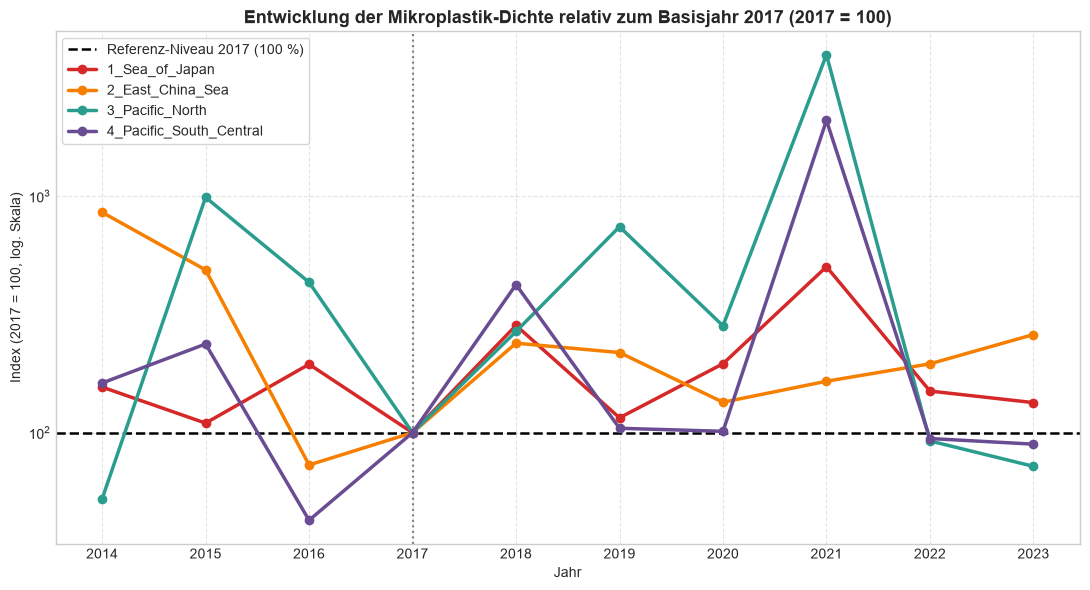

In [12]:
farben_4 = {
    "1_Sea_of_Japan":          "#d62828", # Rot
    "2_East_China_Sea":        "#f77f00", # Orange
    "3_Pacific_North":         "#2a9d8f", # Türkis/Grün
    "4_Pacific_South_Central": "#6a4c93"  # Violett
}

plt.figure(figsize=(11, 6))

# Referenzlinie für 2017 (100 %)
plt.axhline(100, color="black", linestyle="--", linewidth=1.8, label="Referenz-Niveau 2017 (100 %)")
plt.axvline(2017, color="grey", linestyle=":", linewidth=1.5)

for region in df_index_2017.columns:
    plt.plot(
        df_index_2017.index, 
        df_index_2017[region], 
        marker="o", 
        linewidth=2.5, 
        color=farben_4.get(region, "grey"),
        label=region
    )

plt.yscale("log")
plt.title("Entwicklung der Mikroplastik-Dichte relativ zum Basisjahr 2017 (2017 = 100)", fontsize=13, fontweight="bold")
plt.ylabel("Index (2017 = 100, log. Skala)")
plt.xlabel("Jahr")
plt.xticks(df_index_2017.index)
plt.grid(True, which="major", linestyle="--", alpha=0.5)
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.savefig(OUT / "01_index_verlauf_seit_2017.png", dpi=300)
plt.show()

## 6. Plot 2: Direkter Vorher-Nachher-Vergleich (2017 vs. 2023)
Zeigt für jede der 4 Regionen die prozentuale Veränderung vom Basisjahr 2017 bis zum Endjahr 2023.

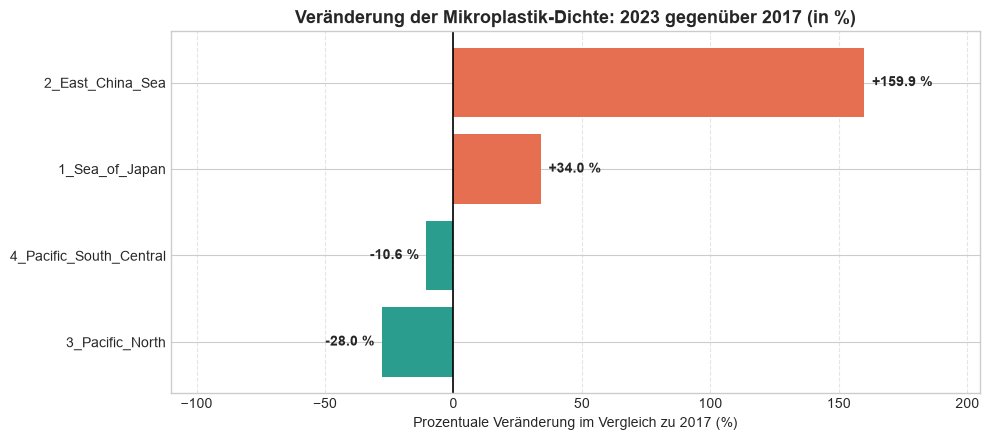

In [13]:
end_jahr = df_diff_2017.index.max()
s_vergleich = df_diff_2017.loc[end_jahr].sort_values()

plt.figure(figsize=(10, 4.5))
balken_farben = ["#2a9d8f" if x < 0 else "#e76f51" for x in s_vergleich]
bars = plt.barh(s_vergleich.index, s_vergleich.values, color=balken_farben)

plt.axvline(0, color="black", linewidth=1.2)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.title(f"Veränderung der Mikroplastik-Dichte: {end_jahr} gegenüber 2017 (in %)", fontsize=13, fontweight="bold")
plt.xlabel("Prozentuale Veränderung im Vergleich zu 2017 (%)")

x_min, x_max = s_vergleich.min(), s_vergleich.max()
plt.xlim(min(-110, x_min - 35), max(40, x_max + 45))

for bar in bars:
    wert = bar.get_width()
    plt.text(
        wert - 3 if wert < 0 else wert + 3, 
        bar.get_y() + bar.get_height()/2,
        f"{wert:+.1f} %", 
        va="center", 
        ha="right" if wert < 0 else "left", 
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(OUT / "02_vergleich_gegenueber_2017.png", dpi=300)
plt.show()

## 7. Plot 3: Kompakte Heatmap der 4 Regionen
Lückenlose Übersicht über alle Jahre und Regionen (ohne `seaborn`).

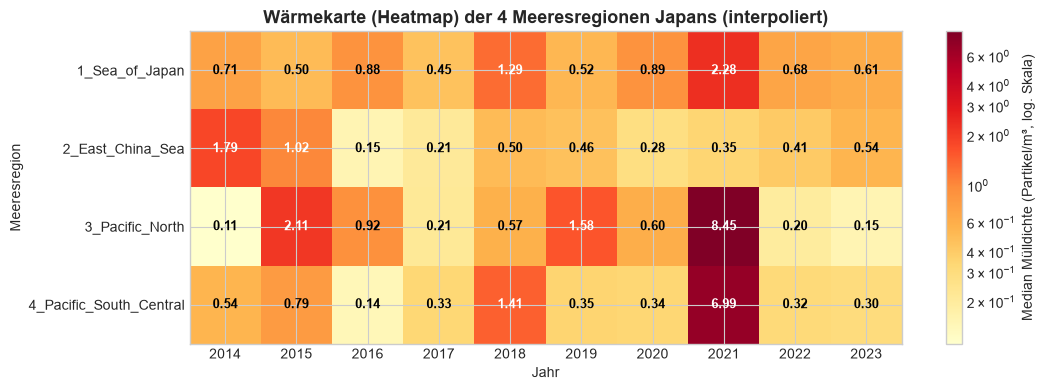

In [14]:
daten_matrix = df.T.values
regionen = df.columns.tolist()
jahre = df.index.tolist()

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(daten_matrix, cmap="YlOrRd", norm=LogNorm(), aspect="auto")

ax.set_xticks(np.arange(len(jahre)))
ax.set_yticks(np.arange(len(regionen)))
ax.set_xticklabels(jahre)
ax.set_yticklabels(regionen)

for i in range(len(regionen)):
    for j in range(len(jahre)):
        wert = daten_matrix[i, j]
        text_farbe = "white" if wert > 1.0 else "black"
        ax.text(j, i, f"{wert:.2f}", ha="center", va="center", color=text_farbe, fontsize=9, fontweight="bold")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Median Mülldichte (Partikel/m³, log. Skala)")

ax.set_title("Wärmekarte (Heatmap) der 4 Meeresregionen Japans (interpoliert)", fontsize=13, fontweight="bold")
ax.set_xlabel("Jahr")
ax.set_ylabel("Meeresregion")
plt.tight_layout()
plt.savefig(OUT / "03_heatmap_4_regionen.png", dpi=300)
plt.show()